# DIT5411 – Traditional Chinese Handwritten Character Recognition (13,065 classes)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/John-ZCT/DIT5411-John_Chu/blob/main/notebooks/DIT5411_Colab.ipynb)

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Runtime → **Run all**.

The notebook is self-contained. It downloads the AI-FREE-Team Traditional Chinese Handwriting
Dataset, preprocesses it, augments the training set with OpenCV, trains three Keras models and
compares their test accuracy. Small cache and result files go to `MyDrive/DIT5411_v2`, so if the
runtime disconnects, **Run all** again continues where it stopped.

| Section | Lecture |
|---|---|
| 2. Data preparation | L11 thresholding and scaling |
| 3. Augmentation | L11 geometric transformations (rotation, translation, scaling, shearing, perspective) |
| 4. Batch loader | L7 normalisation `x / 255.0` |
| 5. Models | L6 MNIST model, L7 CNN, L5 "deep vs fat" |
| 6. Training | L4 softmax cross-entropy, mini-batch, Adam; L5 overfitting (Dropout, EarlyStopping) |
| 7. Evaluation | L7 steps 5–6 (`evaluate`, `predict`, `argmax`) |
| 8. Report | L7 Matplotlib curves |

## 0. Settings
Values you may change are Colab form fields. The defaults are the settings used for the README results.

In [1]:
#@title Settings
import os

IMG_SIZE = 32           #@param {type:"integer"}
PER_CLASS = 240         #@param {type:"integer"}
BATCH_SIZE = 1024       #@param {type:"integer"}
EPOCHS_MLP = 3          #@param {type:"integer"}
EPOCHS_CNN_SIMPLE = 4   #@param {type:"integer"}
EPOCHS_CNN_VGG = 5      #@param {type:"integer"}
MODELS_TO_TRAIN = ["mlp", "cnn_simple", "cnn_vgg"]  #@param {type:"raw"}
SUBSET_CLASSES = 0      #@param {type:"integer"}
AUTO_DISCONNECT = True  #@param {type:"boolean"}
# PER_CLASS = 40 original + 200 augmented training images per character
# SUBSET_CLASSES = 0 uses all 13,065 characters; e.g. 50 is a quick check (output layer stays 13,065)
# AUTO_DISCONNECT = stop the runtime at the end so it doesn't use more GPU quota

SEED = 42
NUM_CLASSES = 13065

# environment variables override the form (used for a headless test run)
LOCAL_TEST = os.environ.get("DIT_LOCAL_TEST") == "1"
SUBSET_CLASSES = int(os.environ.get("DIT_SUBSET_CLASSES", SUBSET_CLASSES))
EPOCHS = {"mlp": EPOCHS_MLP, "cnn_simple": EPOCHS_CNN_SIMPLE, "cnn_vgg": EPOCHS_CNN_VGG}
if "DIT_EPOCHS" in os.environ:
    EPOCHS = {name: int(os.environ["DIT_EPOCHS"]) for name in EPOCHS}

if LOCAL_TEST:
    DRIVE_DIR, WORK = "_local_drive", "work"
    RAW_ZIP = os.environ["DIT_RAW_ZIP"]
    AUTO_DISCONNECT = False
else:
    DRIVE_DIR = "/content/drive/MyDrive/DIT5411_v2"   # small cache + result files
    WORK = "/content/work"                            # local disk: raw data + augmented set
    RAW_ZIP = f"{WORK}/handwritting_data_all/all_data.zip"

# a subset run uses its own file names, so it never mixes with the real run
TAG = f"_sub{SUBSET_CLASSES}" if SUBSET_CLASSES else ""
RESULTS = f"results/subset{SUBSET_CLASSES}" if SUBSET_CLASSES else "results"
print("subset:", SUBSET_CLASSES or "all 13,065 classes", "| epochs:", EPOCHS, "| models:", MODELS_TO_TRAIN)

subset: all 13,065 classes | epochs: {'mlp': 3, 'cnn_simple': 4, 'cnn_vgg': 5} | models: ['mlp', 'cnn_simple', 'cnn_vgg']


## 1. Setup
Check that we are on Colab, mount Google Drive, check the GPU and load a Chinese font for the plots.

In [2]:
import sys, json, time, glob, shutil, subprocess, zipfile, multiprocessing
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # hide TensorFlow info messages

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib import font_manager
import tensorflow as tf
import keras
from keras import layers
from tqdm.auto import tqdm
cv2.setNumThreads(0)   # OpenCV's own threads can hang worker processes after fork

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if not IN_COLAB and not LOCAL_TEST:
    raise RuntimeError("Please open this notebook in Google Colab (use the Open in Colab badge in the README).")

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
for d in [DRIVE_DIR, f"{DRIVE_DIR}/checkpoints", f"{DRIVE_DIR}/logs", f"{DRIVE_DIR}/backup", WORK, RESULTS]:
    os.makedirs(d, exist_ok=True)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    GPU_NAME = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU")
    keras.mixed_precision.set_global_policy("mixed_float16")   # float16 maths on the T4 tensor cores
    print("GPU:", GPU_NAME, "-> mixed_float16 enabled")
else:
    GPU_NAME = "none (CPU)"
    print("WARNING: no GPU found. Choose Runtime -> Change runtime type -> T4 GPU and run again. "
          "Training on the CPU would take many hours.")
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| Keras", keras.__version__,
      "| OpenCV", cv2.__version__)

# Chinese font for matplotlib, otherwise characters show as boxes
NOTO = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
if IN_COLAB and not os.path.exists(NOTO):
    subprocess.run("apt-get -qq install -y fonts-noto-cjk > /dev/null", shell=True)
CJK_FONT = next((f for f in [NOTO, "C:/Windows/Fonts/msjh.ttc", "C:/Windows/Fonts/msyh.ttc"]
                 if os.path.exists(f)), None)
if CJK_FONT:
    font_manager.fontManager.addfont(CJK_FONT)
    plt.rcParams["font.family"] = font_manager.FontProperties(fname=CJK_FONT).get_name()
    plt.rcParams["axes.unicode_minus"] = False
print("CJK font:", CJK_FONT)

def show_char(c):
    """Label for a character in plots (Unicode code point if no Chinese font is available)."""
    return c if CJK_FONT else " ".join(f"U+{ord(x):04X}" for x in c)

def parallel_map(func, items, initializer=None, chunksize=64):
    """Ordered map with a progress bar: all CPU cores on Colab (fork), one process on Windows."""
    if os.name == "nt":
        if initializer:
            initializer()
        yield from tqdm(map(func, items), total=len(items))
    else:
        with multiprocessing.get_context("fork").Pool(os.cpu_count(), initializer) as pool:
            yield from tqdm(pool.imap(func, items, chunksize), total=len(items))

Mounted at /content/drive
GPU: Tesla T4 -> mixed_float16 enabled
Python 3.13.16 | TensorFlow 2.21.0 | Keras 3.13.2 | OpenCV 4.14.0
CJK font: /usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc


## 2. Data preparation (L11 thresholding and scaling)

* **Source:** `chenkenanalytic/handwritting_data_all` on GitHub: 12 byte-split parts of one zip with
  684,677 PNG files at `cleaned_data/<folder id>/<char>_<n>.png` (300×300, dark strokes on white).
* File names are Big5 encoded, so the zip is opened with `metadata_encoding="big5hkscs"`.
  Images are read straight from the zip (never extracted).
* **Classes:** characters sorted by Unicode code point → index 0 … 13,064.
* **Split:** per character, the first 40 samples (by the integer `n`) are training data, the rest are
  test data. A character with 40 or fewer samples has no test samples.
* **Preprocessing:** grayscale → threshold (`cv2.THRESH_BINARY_INV`) to find the strokes → invert
  (white strokes on black) → crop to the strokes → pad to a square with an 8% margin →
  `cv2.resize(..., interpolation=cv2.INTER_AREA)` to 32×32.

The prepared arrays are cached on Drive, so later runs skip this step.

In [3]:
CACHE = f"{DRIVE_DIR}/prepared_{IMG_SIZE}px{TAG}.npz"
CLASSES_JSON = f"{DRIVE_DIR}/classes{TAG}.json"
STATS_JSON = f"{DRIVE_DIR}/data_stats{TAG}.json"
PREVIEW_DRIVE = f"{DRIVE_DIR}/preprocess_preview_{IMG_SIZE}px{TAG}.png"
N_TRAIN = 40          # first 40 samples of each character are training data
INK_THRESHOLD = 30    # a pixel darker than 255 - 30 counts as stroke
MARGIN = 0.08         # empty border around the character

def preprocess(img):
    """L11: grayscale -> threshold -> invert -> crop to strokes -> square with margin -> resize."""
    if img.ndim == 3 and img.shape[2] == 4:                  # composite transparency onto white
        alpha = img[:, :, 3:] / 255.0
        img = (img[:, :, :3] * alpha + 255 * (1 - alpha)).astype(np.uint8)
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mask = cv2.threshold(img, 255 - INK_THRESHOLD, 255, cv2.THRESH_BINARY_INV)   # strokes -> 255
    inverted = 255 - img                                     # white strokes on black, keeps soft edges
    points = cv2.findNonZero(mask)
    if points is None:                                       # blank image
        return np.zeros((IMG_SIZE, IMG_SIZE), np.uint8)
    x, y, w, h = cv2.boundingRect(points)                    # stroke bounding box
    side = int(max(w, h) * (1 + 2 * MARGIN))                 # square canvas keeps the aspect ratio
    canvas = np.zeros((side, side), np.uint8)
    top, left = (side - h) // 2, (side - w) // 2
    canvas[top:top + h, left:left + w] = inverted[y:y + h, x:x + w]
    return cv2.resize(canvas, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)

_zip = None
def open_zip():
    """Each worker process opens its own handle on the zip."""
    global _zip
    _zip = zipfile.ZipFile(RAW_ZIP, metadata_encoding="big5hkscs")   # Big5 names without the UTF-8 flag

def load_image(name):
    if _zip is None:
        open_zip()
    return cv2.imdecode(np.frombuffer(_zip.read(name), np.uint8), cv2.IMREAD_UNCHANGED)

def load_and_preprocess(name):
    return preprocess(load_image(name))

def scan_zip(path):
    """One row per PNG: character, sample number n, folder id, file name inside the zip."""
    rows = []
    with zipfile.ZipFile(path, metadata_encoding="big5hkscs") as zf:
        for name in zf.namelist():
            if name.lower().endswith(".png"):
                folder, file = name.split("/")[-2:]
                char, n = file[:-4].rsplit("_", 1)           # label = text before the last "_"
                rows.append((char, int(n), folder, name))
    return pd.DataFrame(rows, columns=["char", "n", "folder", "name"])

684,677 PNG files, 13,065 characters


  0%|          | 0/684677 [00:00<?, ?it/s]

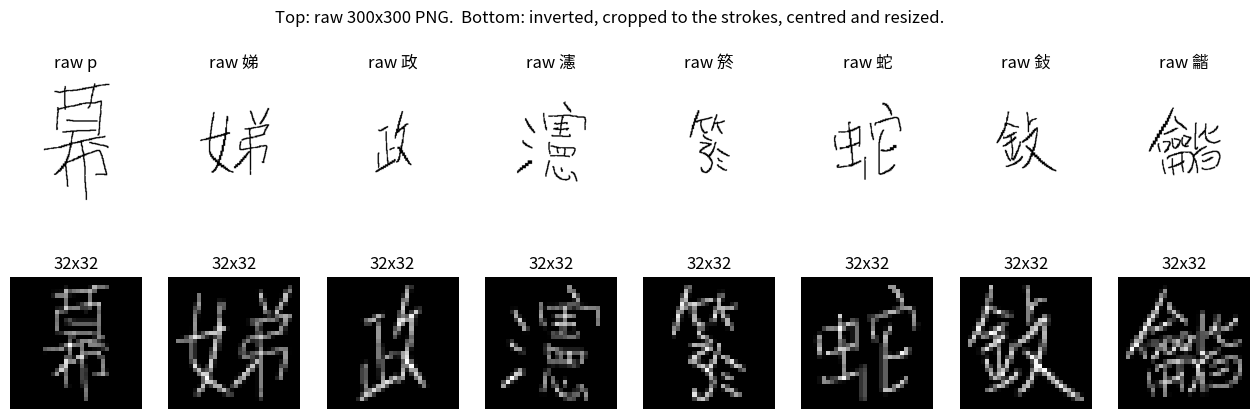

{
  "png_files_in_zip": 684677,
  "characters": 13065,
  "min_samples_per_char": 16,
  "max_samples_per_char": 61,
  "chars_with_40_or_fewer_samples_no_test": 43,
  "train_images_all_chars": 522127,
  "test_images_all_chars": 162550,
  "img_size": 32,
  "subset_classes": 0,
  "prepared_classes": 13065,
  "train_images": 522127,
  "test_images": 162550
}
X_train_orig (522127, 32, 32) y_train_orig (522127,)
X_test       (162550, 32, 32) y_test       (162550,)


In [4]:
if all(os.path.exists(p) for p in [CACHE, CLASSES_JSON, STATS_JSON]):
    print("Loading the prepared data from Drive:", CACHE)
    with np.load(CACHE) as d:
        X_train_orig, y_train_orig, X_test, y_test = d["X_train_orig"], d["y_train_orig"], d["X_test"], d["y_test"]
    classes = json.load(open(CLASSES_JSON, encoding="utf-8"))
    stats = json.load(open(STATS_JSON))
else:
    if not os.path.exists(RAW_ZIP):
        # download (~1.2 GB) and join all_data.zip.001 ... .012 into one zip
        clone_dir = os.path.dirname(RAW_ZIP)
        shutil.rmtree(clone_dir, ignore_errors=True)         # remove a half-finished clone (local disk)
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/chenkenanalytic/handwritting_data_all.git", clone_dir], check=True)
        parts = sorted(glob.glob(f"{clone_dir}/all_data.zip.0*"))
        assert len(parts) == 12, f"expected 12 zip parts, found {len(parts)}"
        subprocess.run(f"cat {clone_dir}/all_data.zip.0* > {RAW_ZIP}.tmp && mv {RAW_ZIP}.tmp {RAW_ZIP}",
                       shell=True, check=True)

    df = scan_zip(RAW_ZIP)
    chars = sorted(df["char"].unique())                      # class index = Unicode code-point order
    print(f"{len(df):,} PNG files, {len(chars):,} characters")
    assert len(chars) == NUM_CLASSES, f"expected {NUM_CLASSES} characters, found {len(chars)}"
    df["label"] = df["char"].map({c: i for i, c in enumerate(chars)})
    df = df.sort_values(["label", "n"]).reset_index(drop=True)       # integer n, so _2 comes before _10
    df["train"] = df.groupby("label").cumcount() < N_TRAIN           # first 40 -> train, rest -> test

    per_char = df.groupby("label").agg(folder=("folder", "first"), n_samples=("n", "size"), n_train=("train", "sum"))
    classes = [{"index": i, "char": chars[i], "folder": r.folder, "n_samples": int(r.n_samples),
                "n_train": int(r.n_train), "n_test": int(r.n_samples - r.n_train)}
               for i, r in enumerate(per_char.itertuples())]

    if SUBSET_CLASSES:                                       # quick check: evenly spread classes only
        keep = np.linspace(0, NUM_CLASSES - 1, SUBSET_CLASSES).astype(int)
        df_used = df[df["label"].isin(keep)]
    else:
        df_used = df
    train_df, test_df = df_used[df_used["train"]], df_used[~df_used["train"]]

    names = list(train_df["name"]) + list(test_df["name"])
    X_all = np.zeros((len(names), IMG_SIZE, IMG_SIZE), np.uint8)
    for i, img in enumerate(parallel_map(load_and_preprocess, names, initializer=open_zip, chunksize=256)):
        X_all[i] = img
    X_train_orig, X_test = X_all[:len(train_df)], X_all[len(train_df):]
    y_train_orig = train_df["label"].to_numpy(np.int32)
    y_test = test_df["label"].to_numpy(np.int32)

    stats = {
        "png_files_in_zip": len(df),
        "characters": NUM_CLASSES,
        "min_samples_per_char": int(per_char.n_samples.min()),
        "max_samples_per_char": int(per_char.n_samples.max()),
        "chars_with_40_or_fewer_samples_no_test": int((per_char.n_samples <= N_TRAIN).sum()),
        "train_images_all_chars": int(df["train"].sum()),
        "test_images_all_chars": int((~df["train"]).sum()),
        "img_size": IMG_SIZE,
        "subset_classes": SUBSET_CLASSES,
        "prepared_classes": int(df_used["label"].nunique()),
        "train_images": len(X_train_orig),
        "test_images": len(X_test),
    }
    np.savez_compressed(CACHE, X_train_orig=X_train_orig, y_train_orig=y_train_orig, X_test=X_test, y_test=y_test)
    json.dump(classes, open(CLASSES_JSON, "w", encoding="utf-8"), ensure_ascii=False)
    json.dump(stats, open(STATS_JSON, "w"), indent=2)

    # preview: raw PNG (top) vs preprocessed image (bottom)
    picks = train_df.iloc[np.linspace(0, len(train_df) - 1, 8).astype(int)]
    plt.figure(figsize=(16, 4.8))
    for i, (name, char) in enumerate(zip(picks["name"], picks["char"])):
        raw = load_image(name)
        plt.subplot(2, 8, i + 1)
        plt.imshow(raw[..., :3][..., ::-1] if raw.ndim == 3 else raw, cmap=plt.get_cmap("gray"))
        plt.title(f"raw {show_char(char)}")
        plt.axis("off")
        plt.subplot(2, 8, 9 + i)
        plt.imshow(preprocess(raw), cmap=plt.get_cmap("gray"))
        plt.title(f"{IMG_SIZE}x{IMG_SIZE}")
        plt.axis("off")
    plt.suptitle("Top: raw 300x300 PNG.  Bottom: inverted, cropped to the strokes, centred and resized.")
    plt.savefig(PREVIEW_DRIVE, dpi=100, bbox_inches="tight")
    plt.show()

    if not LOCAL_TEST:
        shutil.rmtree(os.path.dirname(RAW_ZIP), ignore_errors=True)   # free ~3.6 GB of local disk

shutil.copy(PREVIEW_DRIVE, f"{RESULTS}/preprocess_preview.png")
shutil.copy(STATS_JSON, f"{RESULTS}/data_stats.json")
CHARS = [c["char"] for c in classes]
print(json.dumps(stats, indent=2))
print("X_train_orig", X_train_orig.shape, "y_train_orig", y_train_orig.shape)
print("X_test      ", X_test.shape, "y_test      ", y_test.shape)

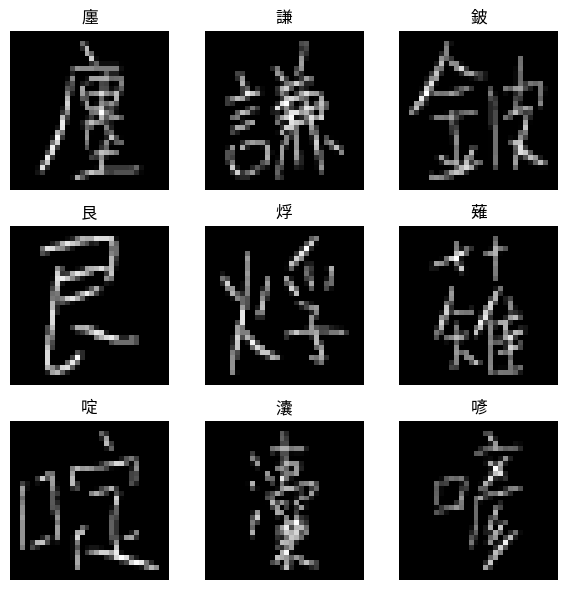

In [5]:
# L7 style: show 9 training images with their characters
rng = np.random.default_rng(SEED)
plt.figure(figsize=(6, 6))
for i, j in enumerate(rng.choice(len(X_train_orig), 9, replace=False)):
    plt.subplot(330 + 1 + i)
    plt.imshow(X_train_orig[j], cmap=plt.get_cmap("gray"))
    plt.title(show_char(CHARS[y_train_orig[j]]))
    plt.axis("off")
plt.tight_layout()
plt.show()

## 3. Data augmentation with OpenCV (L11 geometric transformations)

Each character has only 40 training samples, so we create augmented copies until every character has
**240 training images** (40 originals + 200 augmented). The transformations come from L11:

* rotation – `cv2.getRotationMatrix2D` + `cv2.warpAffine`
* translation – matrix `T = [[1, 0, tx], [0, 1, ty]]` + `cv2.warpAffine`
* scaling – uniform and non-uniform (different x and y factors)
* shearing – matrix `[[1, sh, 0], [0, 1, 0]]` + `cv2.warpAffine`
* perspective (non-affine) – `cv2.getPerspectiveTransform` + `cv2.warpPerspective`
* thicker strokes – `cv2.dilate` (a small extra beyond the lectures)

All matrices are written as 3×3 so they can be multiplied together. **The test set is never augmented.**

In [6]:
# every augmentation parameter in one place (the README lists this table)
AUG = {
    "rotation_deg": 15,         # random rotation in [-15, +15] degrees
    "shear": 0.25,              # horizontal shear factor in [-0.25, +0.25]
    "scale": [0.85, 1.10],      # random zoom factor
    "scale_xy_jitter": 0.05,    # extra +-5% on x and y separately (non-uniform scaling)
    "translate": 0.04,          # shift up to +-4% of the image size
    "perspective_prob": 0.2,    # 20% of the images also get a perspective warp
    "perspective_shift": 0.06,  # each corner moves up to +-6% of the image size
    "dilate_prob": 0.3,         # 30% of the images get thicker strokes
    "dilate_kernel": 2,         # 2x2 kernel; erode is not used, it wipes out 1-pixel strokes at 32 px
}

def rotation_matrix(angle, size):
    """L11: rotate about the image centre."""
    M = cv2.getRotationMatrix2D((size / 2, size / 2), angle, 1.0)
    return np.vstack([M, [0, 0, 1]])

def translation_matrix(tx, ty):
    """L11: T = [[1, 0, tx], [0, 1, ty]]."""
    return np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]], dtype=np.float64)

def scale_matrix(sx, sy, size):
    """Scale about the image centre (sx != sy is non-uniform scaling)."""
    c = size / 2
    return np.array([[sx, 0, (1 - sx) * c], [0, sy, (1 - sy) * c], [0, 0, 1]])

def shear_matrix(sh, size):
    """L11 shear [[1, sh, 0], [0, 1, 0]], shifted so the centre stays in place."""
    return np.array([[1, sh, -sh * size / 2], [0, 1, 0], [0, 0, 1]])

def perspective_matrix(corner_shift, size):
    """L11 non-affine: move the 4 corners and let OpenCV find the 3x3 matrix."""
    src = np.float32([[0, 0], [size, 0], [size, size], [0, size]])
    dst = np.float32(src + corner_shift)
    return cv2.getPerspectiveTransform(src, dst)

def warp(img, M):
    """Apply a 3x3 matrix. borderValue=0 keeps the background black."""
    size = (img.shape[1], img.shape[0])
    if np.allclose(M[2], [0, 0, 1]):                         # affine
        return cv2.warpAffine(img, M[:2], size, flags=cv2.INTER_LINEAR, borderValue=0)
    return cv2.warpPerspective(img, M, size, flags=cv2.INTER_LINEAR, borderValue=0)

def rotate(img, angle):       return warp(img, rotation_matrix(angle, img.shape[0]))
def translate(img, tx, ty):   return warp(img, translation_matrix(tx, ty))
def scale(img, sx, sy=None):  return warp(img, scale_matrix(sx, sy or sx, img.shape[0]))
def shear(img, sh):           return warp(img, shear_matrix(sh, img.shape[0]))
def perspective(img, shift):  return warp(img, perspective_matrix(shift, img.shape[0]))
def thicken(img, k=2):        return cv2.dilate(img, np.ones((k, k), np.uint8))

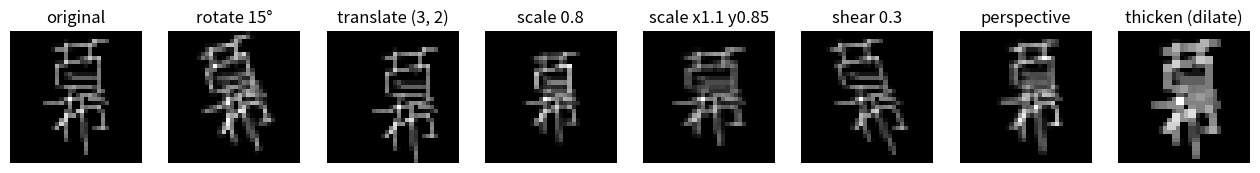

In [7]:
# demo: each transformation applied to the same character
img = X_train_orig[0]
s = IMG_SIZE
demo = {
    "original": img,
    "rotate 15°": rotate(img, 15),
    "translate (3, 2)": translate(img, 3, 2),
    "scale 0.8": scale(img, 0.8),
    "scale x1.1 y0.85": scale(img, 1.1, 0.85),
    "shear 0.3": shear(img, 0.3),
    "perspective": perspective(img, np.float32([[2, 0], [-2, 1], [0, -2], [1, 2]]) * s / 32),
    "thicken (dilate)": thicken(img),
}
plt.figure(figsize=(16, 2.6))
for i, (title, im) in enumerate(demo.items()):
    plt.subplot(1, len(demo), i + 1)
    plt.imshow(im, cmap=plt.get_cmap("gray"))
    plt.title(title)
    plt.axis("off")
plt.show()

In [8]:
def augment_image(img, rng):
    """One random augmentation.

    Scaling, shearing, rotation and translation (and sometimes perspective) are multiplied into ONE
    matrix, so each image is interpolated only once. Applying cv2.warpAffine four times in a row
    would blur a 32x32 character four times.
    """
    size = img.shape[0]
    zoom = rng.uniform(*AUG["scale"])
    jit = AUG["scale_xy_jitter"]
    t = AUG["translate"] * size
    M = (translation_matrix(*rng.uniform(-t, t, 2))
         @ rotation_matrix(rng.uniform(-AUG["rotation_deg"], AUG["rotation_deg"]), size)
         @ shear_matrix(rng.uniform(-AUG["shear"], AUG["shear"]), size)
         @ scale_matrix(zoom * rng.uniform(1 - jit, 1 + jit), zoom * rng.uniform(1 - jit, 1 + jit), size))
    if rng.random() < AUG["perspective_prob"]:
        p = AUG["perspective_shift"] * size
        M = perspective_matrix(rng.uniform(-p, p, (4, 2)), size) @ M
    out = warp(img, M)
    if rng.random() < AUG["dilate_prob"]:
        out = thicken(out, AUG["dilate_kernel"])
    return out

# training images are stored sorted by label, so each character is one slice
assert np.all(np.diff(y_train_orig) >= 0)
counts = np.bincount(y_train_orig, minlength=NUM_CLASSES)
starts = np.concatenate([[0], np.cumsum(counts)])
labels = np.unique(y_train_orig)
assert counts[labels].max() <= PER_CLASS

def augment_class(label):
    """The originals of one character + augmented copies, exactly PER_CLASS images."""
    originals = X_train_orig[starts[label]:starts[label + 1]]
    rng = np.random.default_rng([SEED, int(label)])          # reproducible for each character
    out = np.empty((PER_CLASS, IMG_SIZE, IMG_SIZE), np.uint8)
    n = len(originals)
    out[:n] = originals
    for k in range(n, PER_CLASS):
        out[k] = augment_image(originals[k % n], rng)        # fewer originals -> more copies of each
    return out

In [9]:
# build the augmented training set as a .npy memmap on the LOCAL disk (about 3.2 GB for all classes)
AUG_X = f"{WORK}/train_aug_{IMG_SIZE}px{TAG}.npy"
AUG_Y = f"{WORK}/train_aug_{IMG_SIZE}px{TAG}_labels.npy"
AUG_DONE = f"{WORK}/train_aug_{IMG_SIZE}px{TAG}_done.json"
settings = {"img_size": IMG_SIZE, "per_class": PER_CLASS, "seed": SEED, "classes": len(labels), "aug": AUG}
total = len(labels) * PER_CLASS

if os.path.exists(AUG_DONE) and json.load(open(AUG_DONE)) == settings:
    print("Augmented training set already built:", AUG_X)
else:
    print(f"Building {len(labels):,} x {PER_CLASS} = {total:,} training images ...")
    positions = np.random.default_rng(SEED).permutation(total)     # seeded shuffled order
    X_mm = np.lib.format.open_memmap(AUG_X, mode="w+", dtype=np.uint8, shape=(total, IMG_SIZE, IMG_SIZE))
    y_aug = np.empty(total, np.int32)
    for i, block in enumerate(parallel_map(augment_class, list(labels), chunksize=16)):
        pos = positions[i * PER_CLASS:(i + 1) * PER_CLASS]
        X_mm[pos] = block
        y_aug[pos] = labels[i]
    X_mm.flush()
    del X_mm
    np.save(AUG_Y, y_aug)
    json.dump(settings, open(AUG_DONE, "w"))                       # written last = build finished

X_aug = np.load(AUG_X, mmap_mode="r")
y_aug = np.load(AUG_Y)
per_class = np.bincount(y_aug, minlength=NUM_CLASSES)[labels]
assert (per_class == PER_CLASS).all(), "every character must have exactly PER_CLASS training images"
print(f"Training set: {X_aug.shape[0]:,} images ({len(labels):,} characters x {PER_CLASS}), "
      f"{X_aug.nbytes / 1e9:.2f} GB on local disk")
print(f"Test set (not augmented): {len(X_test):,} images")

Building 13,065 x 240 = 3,135,600 training images ...


  0%|          | 0/13065 [00:00<?, ?it/s]

Training set: 3,135,600 images (13,065 characters x 240), 3.21 GB on local disk
Test set (not augmented): 162,550 images


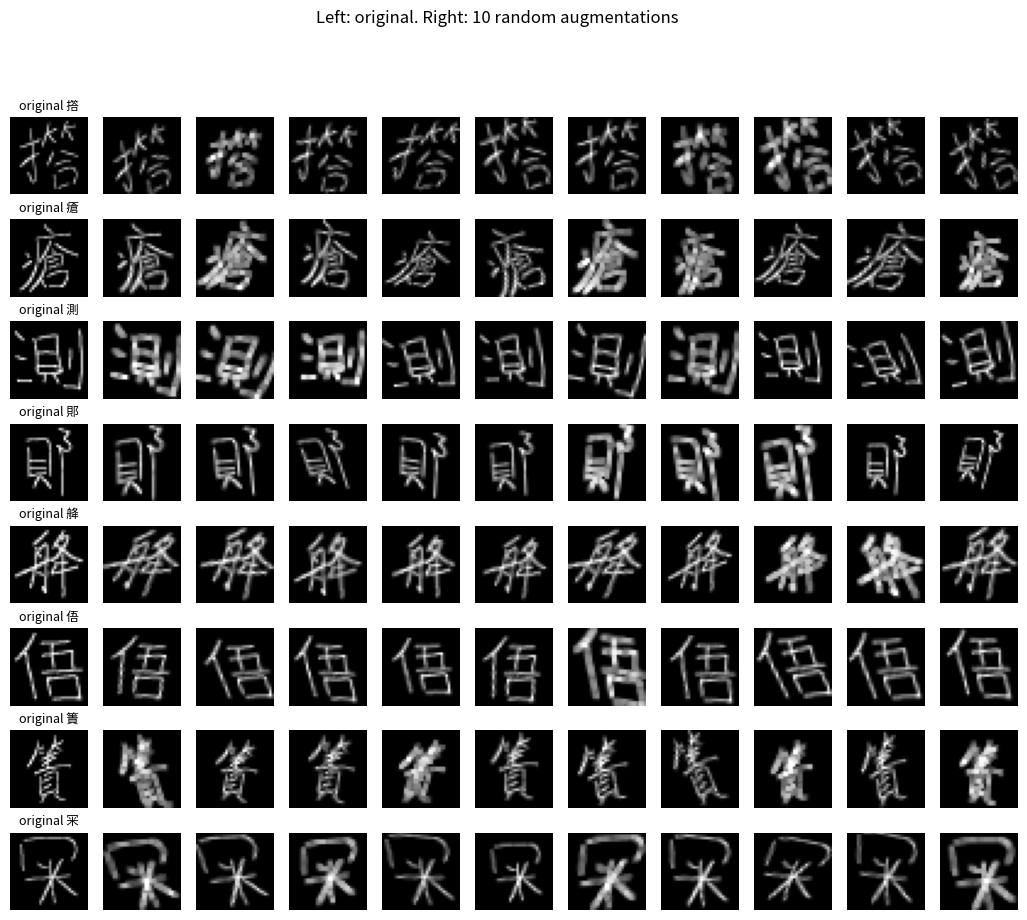

In [10]:
# preview: 8 characters, each with its original and 10 augmented versions
rng = np.random.default_rng(SEED + 1)
picks = rng.choice(labels, min(8, len(labels)), replace=False)
plt.figure(figsize=(13, 1.3 * len(picks)))
for r, label in enumerate(picks):
    original = X_train_orig[starts[label]]
    row = [original] + [augment_image(original, rng) for _ in range(10)]
    for c, im in enumerate(row):
        plt.subplot(len(picks), 11, r * 11 + c + 1)
        plt.imshow(im, cmap=plt.get_cmap("gray"))
        plt.axis("off")
        if c == 0:
            plt.title(f"original {show_char(CHARS[label])}", fontsize=9)
plt.suptitle("Left: original. Right: 10 random augmentations")
plt.savefig(f"{RESULTS}/augmentation_preview.png", dpi=100, bbox_inches="tight")
plt.show()

## 4. Batch loader (L7 normalisation)

The 3.1 million training images stay as uint8 on disk. The loader reads one batch at a time and applies
the L7 normalisation `x / 255.0` per batch (doing it for the whole set at once would need about 13 GB of
float32). The training set is already stored in shuffled order, and the batch order is shuffled again
every epoch. The test set uses the same class without shuffling.

In [11]:
class BatchLoader(keras.utils.PyDataset):
    def __init__(self, X, y, batch_size, shuffle, **kwargs):
        super().__init__(**kwargs)
        self.X, self.y, self.batch_size, self.shuffle = X, y, batch_size, shuffle
        self.order = np.arange(len(self))
        self.rng = np.random.default_rng(SEED)

    def __len__(self):
        return (len(self.X) + self.batch_size - 1) // self.batch_size

    def __getitem__(self, i):
        b = self.order[i]
        s = slice(b * self.batch_size, (b + 1) * self.batch_size)
        x = self.X[s].astype("float32") / 255.0              # L7: x / 255.0
        return x[..., None], self.y[s]                       # add the channel axis -> (batch, 32, 32, 1)

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)

train_loader = BatchLoader(X_aug, y_aug, BATCH_SIZE, shuffle=True, workers=4)
test_loader = BatchLoader(X_test, y_test, BATCH_SIZE, shuffle=False, workers=4)
x, y = train_loader[0]
print("one batch:", x.shape, x.dtype, f"min {x.min():.1f} max {x.max():.1f}", "| labels", y[:8])
print(len(train_loader), "training batches,", len(test_loader), "test batches")

one batch: (1024, 32, 32, 1) float32 min 0.0 max 1.0 | labels [ 8702  3046  4722  4057 12906  2210  9687  4738]
3063 training batches, 159 test batches


## 5. Models (L6 MNIST model, L7 CNN, L5 "deep vs fat")

All three are `keras.Sequential` models with input `(32, 32, 1)` and the same output layer
`Dense(13065, activation='softmax')` (float32 for numerical stability under mixed precision).

* **`mlp`** – the L6 MNIST model, scaled up: Flatten → Dense(512, relu) → Dense(512, relu) → output.
  It sees pixels only, with no idea of neighbourhoods.
* **`cnn_simple`** – the L7 CNN: 3 × [Conv2D 3×3 (32 / 64 / 128 filters, `padding='same'`) →
  MaxPooling 2×2] → Flatten → Dense(512) → Dropout(0.5) → output.
* **`cnn_vgg`** – deeper, VGG style ("deep vs fat", L5): 3 stages × 2 × [Conv2D 3×3 → BatchNormalization
  → ReLU] with 32 / 64 / 128 filters and 2×2 max pooling after each stage → GlobalAveragePooling →
  Dense(512) → BatchNormalization → ReLU → Dropout(0.4) → output.

In [12]:
def build_mlp():
    """L6 MNIST model, scaled up."""
    return keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dense(512, activation="relu"),
        layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
    ], name="mlp")

def build_cnn_simple():
    """L7 CNN: Conv2D + MaxPooling blocks, then Dense + Dropout."""
    return keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(512, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
    ], name="cnn_simple")

def conv_bn_relu(filters):
    return [layers.Conv2D(filters, (3, 3), padding="same"), layers.BatchNormalization(), layers.ReLU()]

def build_cnn_vgg():
    """Deeper VGG-style CNN with BatchNormalization."""
    stack = [keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))]
    for filters in [32, 64, 128]:
        stack += conv_bn_relu(filters) + conv_bn_relu(filters) + [layers.MaxPooling2D((2, 2))]
    stack += [
        layers.GlobalAveragePooling2D(),
        layers.Dense(512),
        layers.BatchNormalization(),
        layers.ReLU(),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32"),
    ]
    return keras.Sequential(stack, name="cnn_vgg")

BUILDERS = {"mlp": build_mlp, "cnn_simple": build_cnn_simple, "cnn_vgg": build_cnn_vgg}

for name in MODELS_TO_TRAIN:
    model = BUILDERS[name]()
    model.summary()
    with open(f"{RESULTS}/{name}_summary.txt", "w", encoding="utf-8") as f:
        model.summary(print_fn=lambda line, **kwargs: f.write(line + "\n"))
    assert model.output_shape[-1] == NUM_CLASSES
    print(f"{name}: {model.count_params():,} parameters, output layer {model.output_shape[-1]:,} units\n")

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 13065)          │     6,702,345 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,489,801 (28.57 MB)

 Trainable params: 7,489,801 (28.57 MB)

 Non-trainable params: 0 (0.00 B)

mlp: 7,489,801 parameters, output layer 13,065 units



... (8 outputs left out)

 Total params: 7,058,665 (26.93 MB)

 Trainable params: 7,056,745 (26.92 MB)

 Non-trainable params: 1,920 (7.50 KB)

cnn_vgg: 7,058,665 parameters, output layer 13,065 units



## 6. Training (L4 softmax cross-entropy and Adam, L5 overfitting)

* **Loss:** `sparse_categorical_crossentropy` is the softmax cross-entropy from L4. It takes the integer
  label directly instead of a `to_categorical` one-hot vector: one-hot labels for 3.1 million images ×
  13,065 classes would need about 160 GB of memory.
* **Optimiser:** Adam, learning rate 0.001, mini-batches of 1024.
* **Metrics:** top-1 accuracy, and top-5 accuracy (the true character is among the 5 highest outputs).
* **Validation data = the test set.** The brief picks the best model by its test accuracy, so the test
  accuracy is reported after each epoch, and the best epoch's weights are kept.
* **Callbacks:** `ModelCheckpoint` (best weights to Drive), `CSVLogger` (history to Drive),
  `EarlyStopping` (L5: stop when test accuracy stops improving), `BackupAndRestore` (resume in the
  middle of a model after a disconnect), and a timer that prints each epoch's time.
* A model that already finished is skipped, so **Run all** after a disconnect continues with the next one.

In [13]:
def compile_model(model):
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy",
                  metrics=["accuracy", keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5")])

class EpochTimer(keras.callbacks.Callback):
    """Prints each epoch's time and adds it to the logs, so CSVLogger saves it too."""
    def on_epoch_begin(self, epoch, logs=None):
        self.start = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs["epoch_time"] = time.time() - self.start
        print(f"  epoch {epoch + 1} took {logs['epoch_time']:.0f} s")

def paths(name):
    return {"ckpt": f"{DRIVE_DIR}/checkpoints/{name}{TAG}.weights.h5",
            "log": f"{DRIVE_DIR}/logs/{name}{TAG}.csv",
            "backup": f"{DRIVE_DIR}/backup/{name}{TAG}",
            "metrics": f"{DRIVE_DIR}/metrics_{name}{TAG}.json"}

def read_log(name):
    """Training history from the CSV log (None if there is none yet)."""
    if not os.path.exists(paths(name)["log"]):
        return None
    log = pd.read_csv(paths(name)["log"]).drop_duplicates("epoch", keep="last")
    return log if len(log) else None

def make_callbacks(name):
    p = paths(name)
    log = read_log(name)
    best_so_far = float(log["val_accuracy"].max()) if log is not None else None   # after a resume
    return [
        EpochTimer(),                                        # first, so the CSV gets epoch_time
        keras.callbacks.BackupAndRestore(p["backup"], delete_checkpoint=True),
        keras.callbacks.ModelCheckpoint(p["ckpt"], monitor="val_accuracy", save_best_only=True,
                                        save_weights_only=True, initial_value_threshold=best_so_far),
        keras.callbacks.CSVLogger(p["log"], append=True),    # append: a resumed run keeps earlier epochs
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=2, restore_best_weights=True),
    ]

def finished(name):
    """Metrics written, or best weights saved and the backup already deleted (= fit() ended)."""
    p = paths(name)
    return os.path.exists(p["metrics"]) or (os.path.exists(p["ckpt"]) and not os.path.exists(p["backup"]))

In [14]:
for name in MODELS_TO_TRAIN:
    if finished(name):
        print(f"{name}: already trained, skipping")
        continue
    keras.backend.clear_session()
    model = BUILDERS[name]()
    compile_model(model)
    print(f"Training {name} for up to {EPOCHS[name]} epochs ({len(train_loader)} batches per epoch)")
    model.fit(train_loader, epochs=EPOCHS[name], validation_data=test_loader,
              callbacks=make_callbacks(name), verbose=1 if IN_COLAB else 2)

Training mlp for up to 3 epochs (3063 batches per epoch)
Epoch 1/3
3061/3063 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.1105 - loss: 6.1818 - top5: 0.2279  epoch 1 took 70 s
3063/3063 ━━━━━━━━━━━━━━━━━━━━ 71s 22ms/step - accuracy: 0.2314 - loss: 4.5108 - top5: 0.4252 - val_accuracy: 0.4224 - val_loss: 2.6998 - val_top5: 0.6881 - epoch_time: 69.7869
Epoch 2/3
3062/3063 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.5088 - loss: 2.2095 - top5: 0.7592  epoch 2 took 65 s
3063/3063 ━━━━━━━━━━━━━━━━━━━━ 68s 22ms/step - accuracy: 0.5455 - loss: 2.0000 - top5: 0.7894 - val_accuracy: 0.5405 - val_loss: 2.0710 - val_top5: 0.7923 - epoch_time: 64.5257
Epoch 3/3
3063/3063 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.6652 - loss: 1.3676 - top5: 0.8770  epoch 3 took 65 s
3063/3063 ━━━━━━━━━━━━━━━━━━━━ 69s 23ms/step - accuracy: 0.6739 - loss: 1.3189 - top5: 0.8832 - val_accuracy: 0.5847 - val_loss: 1.9228 - val_top5: 0.8248 - epoch_time: 65.1010
Training cnn_simple for up to 4 epochs (3063 b

## 7. Evaluation (L7 steps 5 and 6)

For each model: load the best weights, run `model.evaluate` on the whole test set, save the metrics,
then `model.predict` + `tf.argmax` on some test images and show the mistakes.

159/159 ━━━━━━━━━━━━━━━━━━━━ 4s 16ms/step - accuracy: 0.5847 - loss: 1.9228 - top5: 0.8248
{
  "model": "mlp",
  "params": 7489801,
  "epochs_run": 3,
  "best_epoch": 3,
  "train_seconds": 199,
  "img_size": 32,
  "train_images": 3135600,
  "test_images": 162550,
  "test_loss": 1.9228,
  "test_top1": 0.5847,
  "test_top5": 0.8248,
  "gpu": "Tesla T4",
  "subset_classes": 0
}


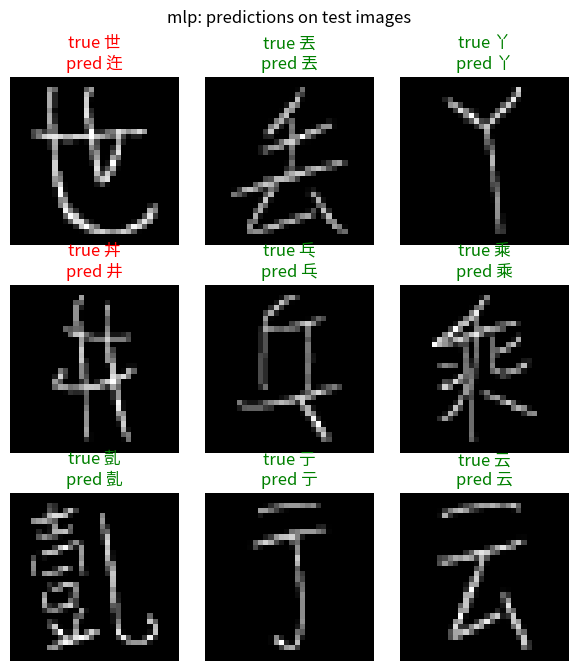

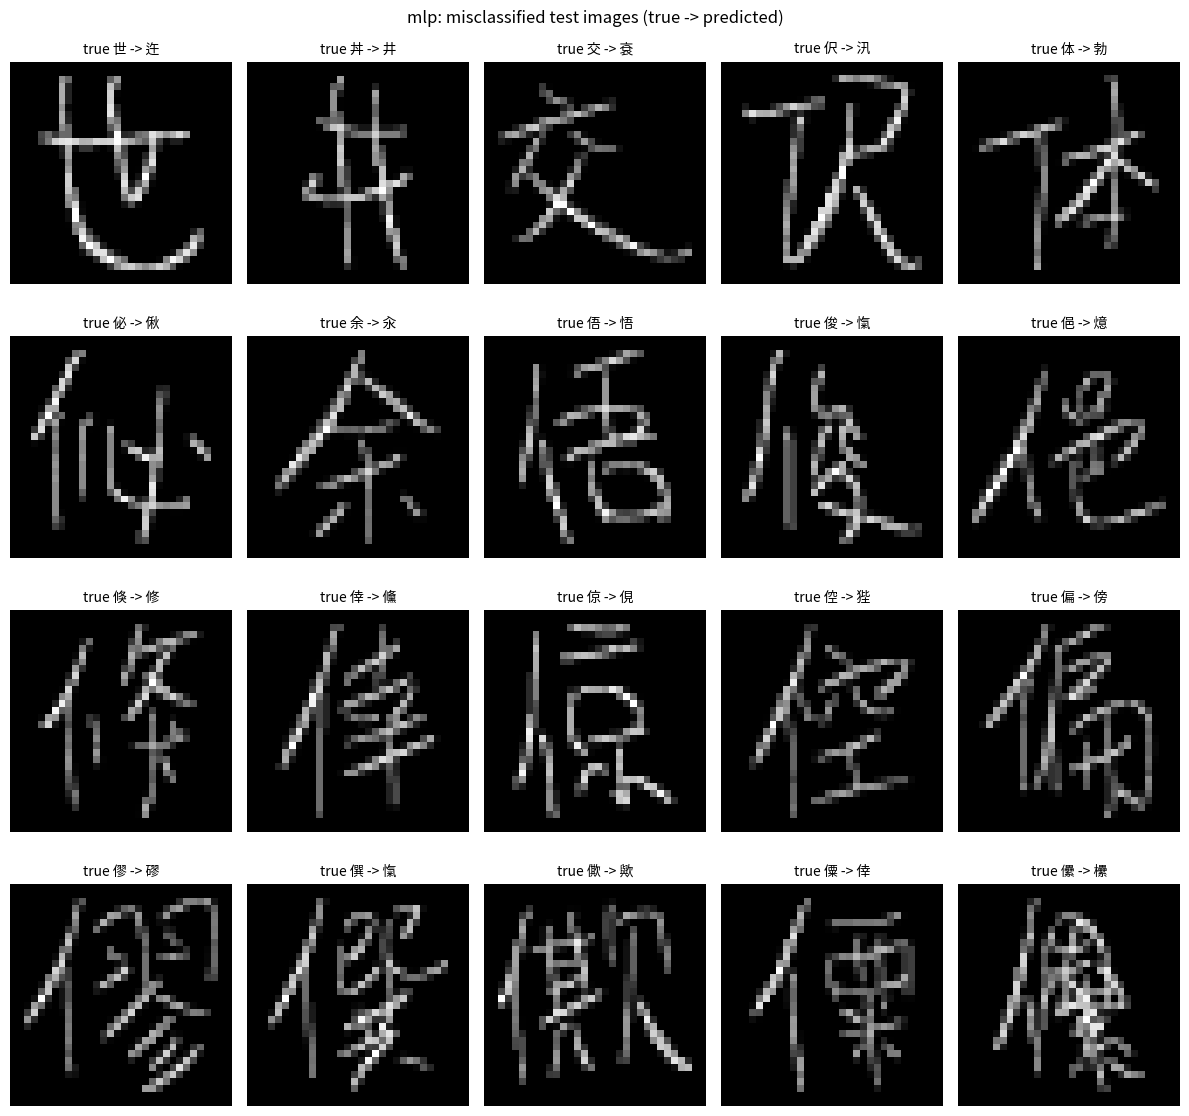

mlp: 850 of 2048 sampled test images wrong
159/159 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8556 - loss: 0.5946 - top5: 0.9758
{
  "model": "cnn_simple",
  "params": 7844105,
  "epochs_run": 4,
  "best_epoch": 4,
  "train_seconds": 696,
  "img_size": 32,
  "train_images": 3135600,
  "test_images": 162550,
  "test_loss": 0.5946,
  "test_top1": 0.8556,
  "test_top5": 0.9758,
  "gpu": "Tesla T4",
  "subset_classes": 0
}


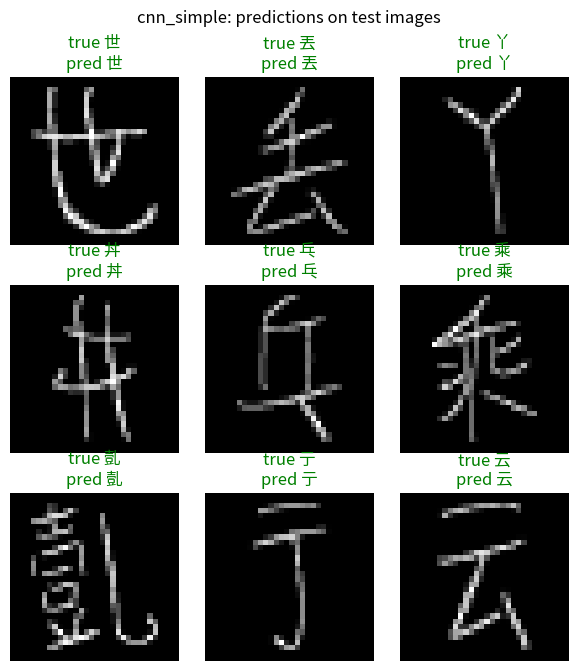

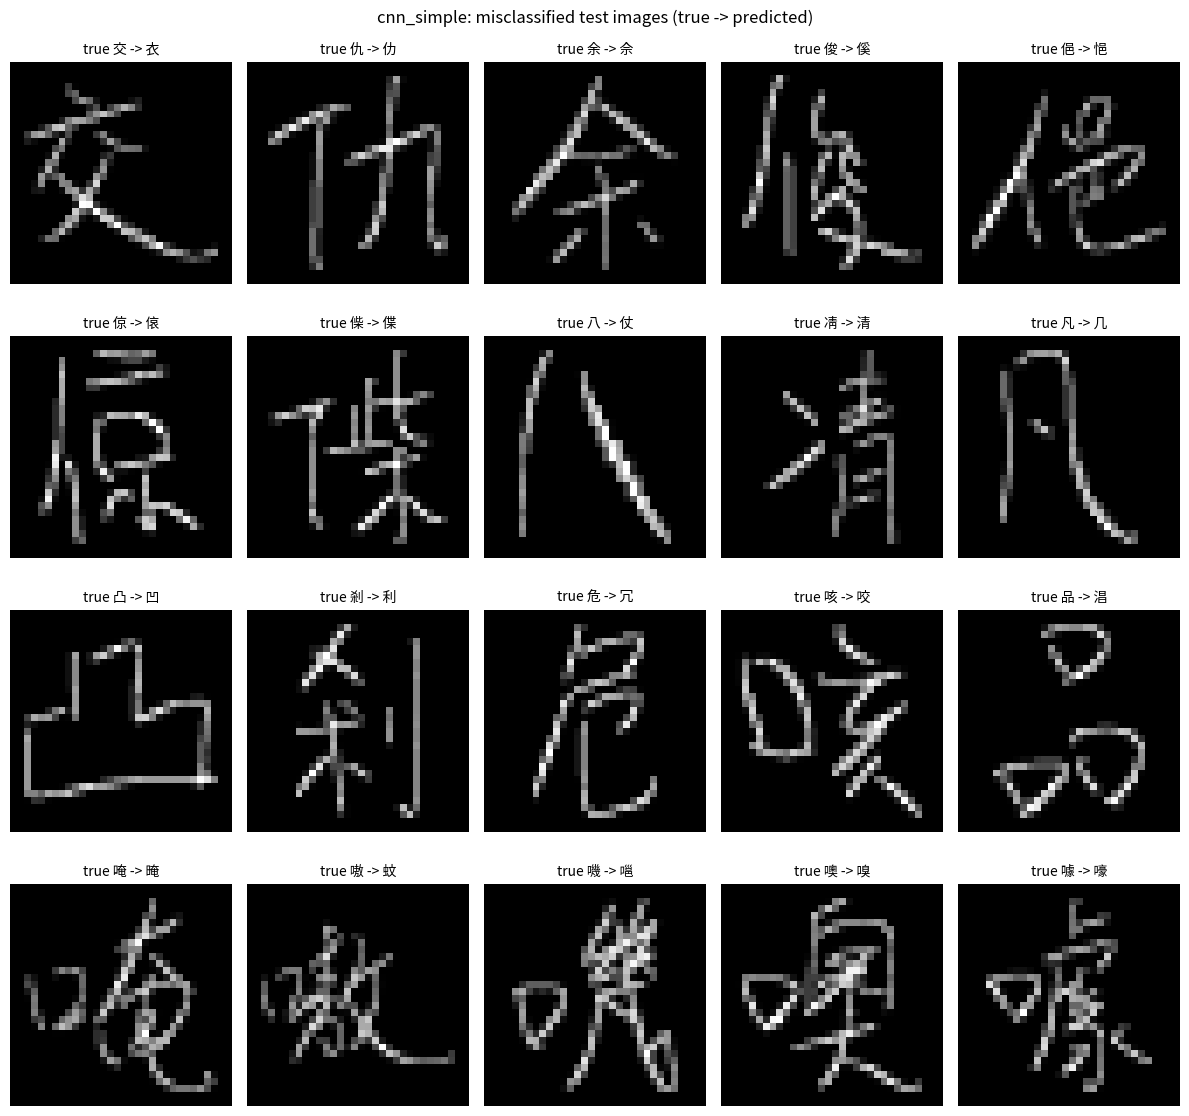

cnn_simple: 315 of 2048 sampled test images wrong
159/159 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.9665 - loss: 0.1299 - top5: 0.9973
{
  "model": "cnn_vgg",
  "params": 7058665,
  "epochs_run": 5,
  "best_epoch": 5,
  "train_seconds": 1845,
  "img_size": 32,
  "train_images": 3135600,
  "test_images": 162550,
  "test_loss": 0.1299,
  "test_top1": 0.9665,
  "test_top5": 0.9973,
  "gpu": "Tesla T4",
  "subset_classes": 0
}


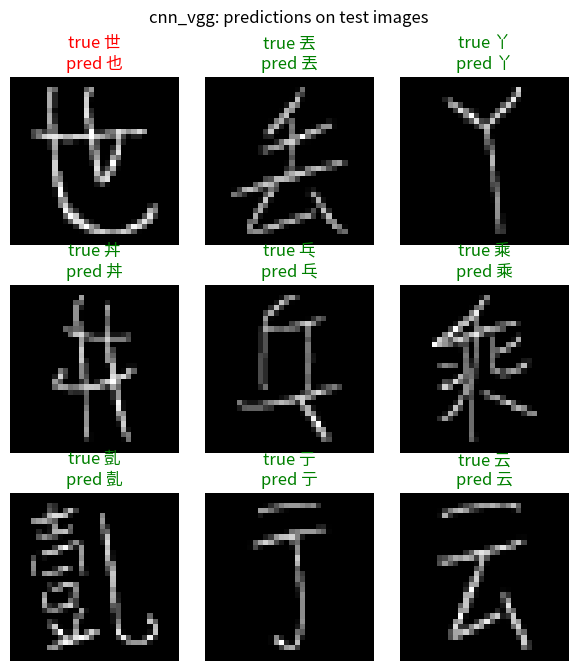

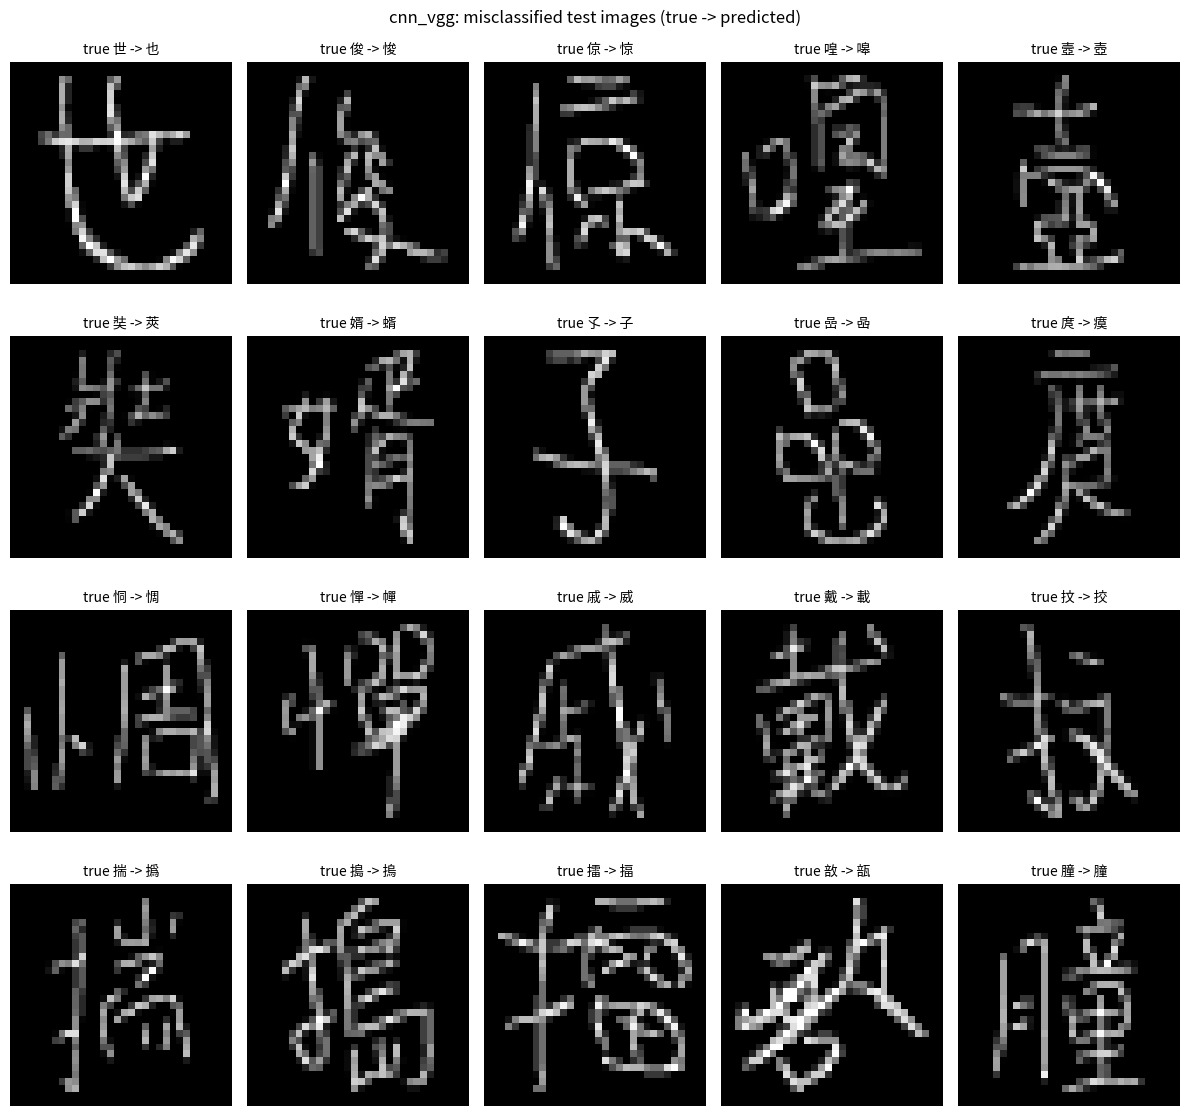

cnn_vgg: 80 of 2048 sampled test images wrong


In [15]:
rng = np.random.default_rng(SEED)
sample = np.sort(rng.choice(len(X_test), min(2048, len(X_test)), replace=False))   # same images for every model
x_sample = X_test[sample][..., None] / 255.0
true = y_test[sample]

for name in MODELS_TO_TRAIN:
    p = paths(name)
    if not os.path.exists(p["ckpt"]):
        print(f"{name}: no weights found, skipping")
        continue
    keras.backend.clear_session()
    model = BUILDERS[name]()
    model.load_weights(p["ckpt"])                            # best epoch (before compile: no optimizer state needed)
    compile_model(model)

    if os.path.exists(p["metrics"]):
        metrics = json.load(open(p["metrics"]))
    else:
        loss, acc, top5 = model.evaluate(test_loader, verbose=1 if IN_COLAB else 2)   # L7 step 5
        log = read_log(name)
        metrics = {
            "model": name,
            "params": model.count_params(),
            "epochs_run": len(log),
            "best_epoch": int(log.loc[log["val_accuracy"].idxmax(), "epoch"]) + 1,
            "train_seconds": round(float(log["epoch_time"].sum())),
            "img_size": IMG_SIZE,
            "train_images": len(y_aug),
            "test_images": len(y_test),
            "test_loss": round(float(loss), 4),
            "test_top1": round(float(acc), 4),
            "test_top5": round(float(top5), 4),
            "gpu": GPU_NAME,
            "subset_classes": SUBSET_CLASSES,
        }
        json.dump(metrics, open(p["metrics"], "w"), indent=2)
    shutil.copy(p["metrics"], f"{RESULTS}/metrics_{name}.json")
    print(json.dumps(metrics, indent=2))

    # L7 step 6: predict and take the class with the highest probability
    probs = model.predict(x_sample, batch_size=256, verbose=0)
    pred = tf.argmax(probs, axis=1).numpy()

    plt.figure(figsize=(6, 6.8))
    for i in range(9):
        plt.subplot(330 + 1 + i)
        plt.imshow(x_sample[i, :, :, 0], cmap=plt.get_cmap("gray"))
        ok = pred[i] == true[i]
        plt.title(f"true {show_char(CHARS[true[i]])}\npred {show_char(CHARS[pred[i]])}",
                  color="green" if ok else "red")
        plt.axis("off")
    plt.suptitle(f"{name}: predictions on test images")
    plt.tight_layout()
    plt.show()

    wrong = np.flatnonzero(pred != true)[:20]
    if len(wrong):
        plt.figure(figsize=(12, 2.9 * ((len(wrong) + 4) // 5)))
        for i, j in enumerate(wrong):
            plt.subplot((len(wrong) + 4) // 5, 5, i + 1)
            plt.imshow(x_sample[j, :, :, 0], cmap=plt.get_cmap("gray"))
            plt.title(f"true {show_char(CHARS[true[j]])} -> {show_char(CHARS[pred[j]])}", fontsize=10)
            plt.axis("off")
        plt.suptitle(f"{name}: misclassified test images (true -> predicted)")
        plt.tight_layout()
        plt.savefig(f"{RESULTS}/misclassified_{name}.png", dpi=100, bbox_inches="tight")
        plt.show()
    print(f"{name}: {len(np.flatnonzero(pred != true))} of {len(sample)} sampled test images wrong")

## 8. Report and finish (L7 Matplotlib)

Accuracy and loss curves, a comparison chart and a summary table, all saved in `results/`. The folder is
zipped as `results_32px.zip`, copied to Drive and downloaded.

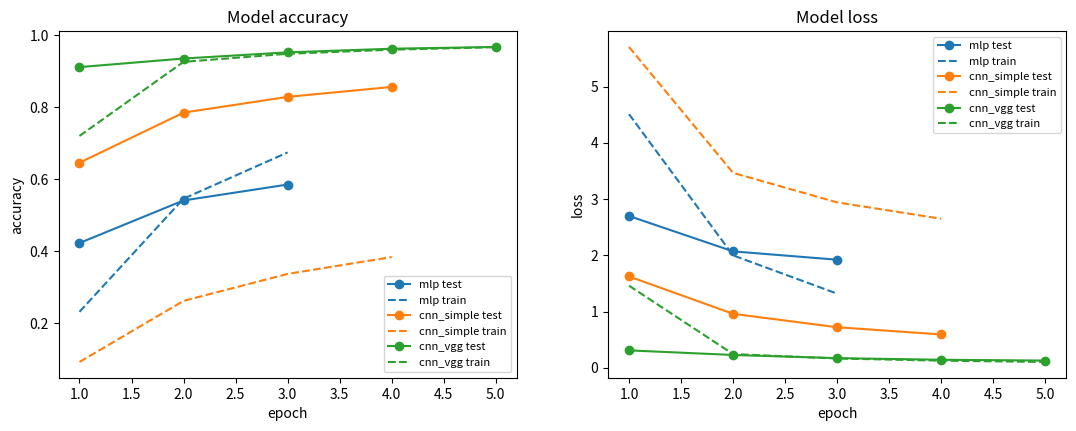

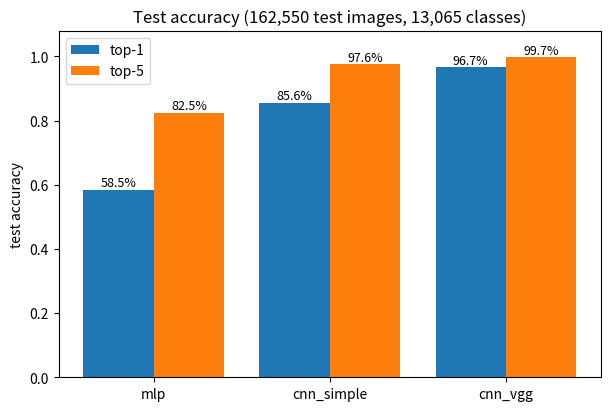

# Results (32x32 px, 240 training images per character)

Training images: 3,135,600. Test images: 162,550 (not augmented, also used as validation data).
GPU: Tesla T4. Subset: none (all 13,065 classes).

| Model | Parameters | Epochs run (best) | Training time | Test top-1 | Test top-5 |
|---|---:|---:|---:|---:|---:|
| mlp | 7,489,801 | 3 (3) | 3.3 min | 58.47% | 82.48% |
| cnn_simple | 7,844,105 | 4 (4) | 11.6 min | 85.56% | 97.58% |
| **cnn_vgg** | **7,058,665** | **5 (5)** | **30.8 min** | **96.65%** | **99.73%** |

Best model: **cnn_vgg**


In [16]:
done = [n for n in MODELS_TO_TRAIN if os.path.exists(f"{RESULTS}/metrics_{n}.json")]
all_metrics = {n: json.load(open(f"{RESULTS}/metrics_{n}.json")) for n in done}

# accuracy and loss curves from the CSV logs
os.makedirs(f"{RESULTS}/logs", exist_ok=True)
plt.figure(figsize=(13, 4.5))
for name in done:
    log = read_log(name)
    log.to_csv(f"{RESULTS}/logs/{name}.csv", index=False)
    epochs = log["epoch"] + 1
    plt.subplot(1, 2, 1)
    line, = plt.plot(epochs, log["val_accuracy"], marker="o", label=f"{name} test")
    plt.plot(epochs, log["accuracy"], linestyle="--", color=line.get_color(), label=f"{name} train")
    plt.subplot(1, 2, 2)
    plt.plot(epochs, log["val_loss"], marker="o", color=line.get_color(), label=f"{name} test")
    plt.plot(epochs, log["loss"], linestyle="--", color=line.get_color(), label=f"{name} train")
for i, metric in enumerate(["accuracy", "loss"]):
    plt.subplot(1, 2, i + 1)
    plt.title(f"Model {metric}")
    plt.xlabel("epoch")
    plt.ylabel(metric)
    plt.legend(fontsize=8)
plt.savefig(f"{RESULTS}/accuracy_curves.png", dpi=100, bbox_inches="tight")
plt.show()

# bar chart of test top-1 and top-5 accuracy
x = np.arange(len(done))
top1 = [all_metrics[n]["test_top1"] for n in done]
top5 = [all_metrics[n]["test_top5"] for n in done]
plt.figure(figsize=(7, 4.5))
plt.bar(x - 0.2, top1, 0.4, label="top-1")
plt.bar(x + 0.2, top5, 0.4, label="top-5")
for i in range(len(done)):
    plt.text(x[i] - 0.2, top1[i] + 0.01, f"{top1[i]:.1%}", ha="center", fontsize=9)
    plt.text(x[i] + 0.2, top5[i] + 0.01, f"{top5[i]:.1%}", ha="center", fontsize=9)
plt.xticks(x, done)
plt.ylim(0, 1.08)
plt.ylabel("test accuracy")
plt.title(f"Test accuracy ({len(y_test):,} test images, {NUM_CLASSES:,} classes)")
plt.legend()
plt.savefig(f"{RESULTS}/model_comparison.png", dpi=100, bbox_inches="tight")
plt.show()

# summary table, best model in bold
best = max(done, key=lambda n: all_metrics[n]["test_top1"]) if done else None
rows = ["| Model | Parameters | Epochs run (best) | Training time | Test top-1 | Test top-5 |",
        "|---|---:|---:|---:|---:|---:|"]
for n in done:
    m = all_metrics[n]
    cells = [n, f"{m['params']:,}", f"{m['epochs_run']} ({m['best_epoch']})", f"{m['train_seconds'] / 60:.1f} min",
             f"{m['test_top1']:.2%}", f"{m['test_top5']:.2%}"]
    rows.append("| " + " | ".join(f"**{c}**" if n == best else c for c in cells) + " |")
summary = "\n".join([
    f"# Results ({IMG_SIZE}x{IMG_SIZE} px, {PER_CLASS} training images per character)", "",
    f"Training images: {len(y_aug):,}. Test images: {len(y_test):,} (not augmented, also used as validation data).",
    f"GPU: {GPU_NAME}. Subset: {SUBSET_CLASSES or 'none (all 13,065 classes)'}.", "",
    *rows, "",
    f"Best model: **{best}**" if best else "No model finished yet.",
])
open(f"{RESULTS}/summary.md", "w", encoding="utf-8").write(summary + "\n")
print(summary)

In [2]:
# zip results/ (without subset folders), copy it to Drive and download it
ZIP_NAME = f"results_{IMG_SIZE}px{TAG}.zip"
with zipfile.ZipFile(ZIP_NAME, "w", zipfile.ZIP_DEFLATED) as z:
    for path in glob.glob(f"{RESULTS}/**/*", recursive=True):
        rel = os.path.relpath(path, RESULTS)
        if os.path.isfile(path) and not rel.startswith("subset"):
            z.write(path, rel)
shutil.copy(ZIP_NAME, f"{DRIVE_DIR}/{ZIP_NAME}")
print(f"{ZIP_NAME}: {os.path.getsize(ZIP_NAME) / 1e6:.1f} MB, copy saved to {DRIVE_DIR}")

drive_bytes = sum(os.path.getsize(os.path.join(root, f)) for root, _, files in os.walk(DRIVE_DIR) for f in files)
print(f"Drive folder {DRIVE_DIR}: {drive_bytes / 1e9:.2f} GB")

if IN_COLAB:
    from google.colab import files
    files.download(ZIP_NAME)
    if AUTO_DISCONNECT:
        print("Disconnecting in 30 s to save GPU quota (the zip is also on Drive) ...")
        time.sleep(30)
        from google.colab import runtime
        runtime.unassign()

NameError: name 'IMG_SIZE' is not defined